# Đề 9 — E-Commerce Customer Segmentation

## Notebook 02 — Tính RFM và Tiền xử lý

**Đầu vào:** `data/retail_clean.parquet` (từ notebook 01)

**Mục tiêu**

1. Tính ba chỉ số RFM cho từng khách hàng
2. Khảo sát phân phối, định lượng độ lệch
3. Xử lý độ lệch bằng `log1p`, chuẩn hóa bằng `StandardScaler`
4. Xuất dữ liệu sẵn sàng cho phân cụm

**Đầu ra:** `data/rfm.parquet` (RFM thô, dùng để diễn giải cụm)
và `data/rfm_scaled.parquet` (đã chuẩn hóa, dùng để phân cụm)

**Thứ tự xử lý bắt buộc**

```
RFM thô  →  log1p  →  StandardScaler  →  phân cụm
```

Hai phép biến đổi giải quyết hai vấn đề khác nhau và **không thay thế được cho nhau**:
`log1p` sửa *hình dạng* phân phối, `StandardScaler` cân bằng *thang đo* giữa ba chiều.
Đảo thứ tự sẽ hỏng — lý do trình bày ở mục 5.1.

---

## 0. Thiết lập

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

DATA       = Path('data')
CLEAN_IN   = DATA / 'retail_clean.parquet'
RFM_OUT    = DATA / 'rfm.parquet'
SCALED_OUT = DATA / 'rfm_scaled.parquet'

COLS  = ['Recency', 'Frequency', 'Monetary']
COLOR = '#4C78A8'

print('pandas', pd.__version__)

pandas 3.0.5


---

## 1. Nạp dữ liệu sạch

In [2]:
clean = pd.read_parquet(CLEAN_IN)

print(f'{len(clean):>10,} dòng')
print(f'{clean["Customer ID"].nunique():>10,} khách hàng')
print(f'{clean["Invoice"].nunique():>10,} hóa đơn')
print()
print('Kiểm tra dữ liệu đã sạch:')
print(f'  Quantity <= 0  : {(clean["Quantity"] <= 0).sum()}')
print(f'  Price <= 0     : {(clean["Price"] <= 0).sum()}')
print(f'  Customer ID NA : {clean["Customer ID"].isna().sum()}')

   770,451 dòng
     5,839 khách hàng
    36,324 hóa đơn

Kiểm tra dữ liệu đã sạch:
  Quantity <= 0  : 0
  Price <= 0     : 0
  Customer ID NA : 0


---

## 2. Tính RFM

### 2.1 Ngày tham chiếu

Recency được đo ngược từ một mốc thời gian cố định. Mốc này lấy bằng
**ngày cuối cùng trong dữ liệu cộng thêm một ngày**.

Lý do cộng 1: nếu lấy đúng ngày cuối, khách mua hôm đó sẽ có $R = 0$. Giá trị 0
gây hai phiền toái — khó diễn giải ("mua cách đây 0 ngày") và làm lệch phân phối
ở biên trái khi biến đổi.

In [3]:
last_date     = clean['InvoiceDate'].max()
snapshot_date = last_date.normalize() + pd.Timedelta(days=1)

print('Giao dịch cuối cùng :', last_date)
print('Ngày tham chiếu     :', snapshot_date)

Giao dịch cuối cùng : 2011-12-09 12:50:00
Ngày tham chiếu     : 2011-12-10 00:00:00


### 2.2 Gom nhóm theo khách hàng

| Chỉ số | Cách tính | Lưu ý |
|---|---|---|
| **Recency** | `ngày tham chiếu − ngày mua gần nhất` | đơn vị ngày, **thấp là tốt** |
| **Frequency** | số `Invoice` **khác nhau** | đếm hóa đơn, không đếm dòng |
| **Monetary** | tổng `TotalPrice` | đơn vị bảng Anh |

Điểm dễ sai nhất là **Frequency**. Một khách mua 20 món trong cùng một đơn sẽ
sinh ra 20 dòng, nhưng đó vẫn chỉ là **một** lần mua. Dùng `nunique` chứ không
dùng `count` hay `size`.

In [4]:
rfm = clean.groupby('Customer ID').agg(
    LastPurchase=('InvoiceDate', 'max'),
    Frequency=('Invoice', 'nunique'),
    Monetary=('TotalPrice', 'sum'),
)

rfm['Recency'] = (snapshot_date - rfm['LastPurchase'].dt.normalize()).dt.days
rfm = rfm[['Recency', 'Frequency', 'Monetary', 'LastPurchase']]

print(f'{len(rfm):,} khách hàng')
rfm.head(10)

5,839 khách hàng


,Recency,Frequency,Monetary,LastPurchase
Customer ID,,,,
12346,530,2,169.360,2010-06-28 13:53:00
12347,3,8,"4,921.530",2011-12-07 15:52:00
12348,76,5,"1,658.400",2011-09-25 13:13:00
12349,19,3,"3,678.690",2011-11-21 09:51:00
12350,311,1,294.400,2011-02-02 16:01:00
12351,376,1,300.930,2010-11-29 15:23:00
12352,37,8,"1,609.210",2011-11-03 14:37:00
12353,205,2,406.760,2011-05-19 17:47:00
12354,233,1,"1,079.400",2011-04-21 13:11:00


### 2.3 Kiểm tra tính hợp lệ

Ba điều kiện phải đúng, nếu sai thì có lỗi ở bước làm sạch:

- `Monetary > 0` với mọi khách — vì notebook 01 đã bỏ hết `Quantity <= 0` và `Price <= 0`.
  Điều kiện này **bắt buộc** cho `log1p` ở mục 4.
- `Frequency >= 1` — khách nào có mặt trong dữ liệu thì phải có ít nhất một hóa đơn.
- `Recency >= 1` — vì ngày tham chiếu đã cộng thêm một ngày.

In [5]:
assert (rfm['Monetary']  > 0).all(), 'Có khách Monetary <= 0 — log1p sẽ lỗi'
assert (rfm['Frequency'] >= 1).all(), 'Có khách Frequency < 1'
assert (rfm['Recency']   >= 1).all(), 'Có khách Recency < 1'

print('Ba điều kiện hợp lệ: PASS')
print()
print(f'Recency  : {rfm["Recency"].min():>6,} .. {rfm["Recency"].max():>10,} ngày')
print(f'Frequency: {rfm["Frequency"].min():>6,} .. {rfm["Frequency"].max():>10,} hóa đơn')
print(f'Monetary : {rfm["Monetary"].min():>6,.0f} .. {rfm["Monetary"].max():>10,.0f} bảng')

Ba điều kiện hợp lệ: PASS

Recency  :      1 ..        739 ngày
Frequency:      1 ..        369 hóa đơn
Monetary :      3 ..    579,129 bảng


---

## 3. Phân tích phân phối

### 3.1 Thống kê mô tả

In [6]:
rfm[COLS].describe()

,Recency,Frequency,Monetary
count,"5,839.000","5,839.000","5,839.000"
mean,200.906,6.221,"2,818.846"
std,208.608,12.632,"13,867.593"
min,1.000,1.000,2.900
25%,26.000,1.000,336.245
50%,96.000,3.000,851.880
75%,380.000,7.000,"2,206.485"
max,739.000,369.000,"579,128.640"


### 3.2 Độ lệch và lựa chọn phép chuẩn hóa

Hai chỉ báo quyết định cách xử lý tiếp theo:

**Skewness** đo độ lệch của phân phối. Bằng 0 là đối xứng; dương là lệch phải
(đuôi dài bên phải); trên 1 được coi là lệch mạnh.

**Tỉ lệ max / median** cho biết giá trị lớn nhất có phải là giá trị đại diện hay
chỉ là một outlier cô lập:

| Tỉ lệ | Kết luận |
|---|---|
| dưới ~10 | min-max dùng được |
| 10 – 100 | cần xem phân phối trước khi quyết định |
| trên ~100 | min-max hỏng, phải log transform trước |

In [7]:
diag = pd.DataFrame({
    'skewness'   : rfm[COLS].skew(),
    'mean'       : rfm[COLS].mean(),
    'median'     : rfm[COLS].median(),
    'max'        : rfm[COLS].max(),
})
diag['mean/median'] = diag['mean'] / diag['median']
diag['max/median']  = diag['max']  / diag['median']

print(diag.to_string())

           skewness      mean  median         max  mean/median  max/median
Recency       0.894   200.906  96.000     739.000        2.093       7.698
Frequency    11.965     6.221   3.000     369.000        2.074     123.000
Monetary     26.740 2,818.846 851.880 579,128.640        3.309     679.824


**Đọc kết quả**

| Chiều | Skewness | max / median | Kết luận |
|---|---|---|---|
| Recency | 0,89 | 7,7 | lệch nhẹ, không có giá trị cực đoan — Recency bị chặn trên bởi độ dài dữ liệu (739 ngày) |
| Frequency | 12,0 | 123 | lệch rất mạnh: một nửa số khách mua tối đa 3 lần, nhưng có khách mua 369 lần |
| Monetary | 26,7 | 680 | lệch cực mạnh: khách chi nhiều nhất gấp **680 lần** khách điển hình |

Với Monetary, nếu dùng min-max thì khách điển hình nhận giá trị khoảng $1/680 \approx 0{,}0015$:
gần như toàn bộ khách bị ép sát về 0, chỉ vài khách bán buôn được trải ra. Hai chiều
F và M **bắt buộc** phải log trước khi chuẩn hóa.

Trung bình gấp 2–3 lần trung vị ở cả ba chiều, nên ở notebook 03 mọi mô tả cụm đều dùng
**trung vị**.

---

## 4. Xử lý độ lệch bằng `log1p`

### 4.1 Vì sao là logarit

Logarit **biến tỉ lệ thành hiệu**: mỗi lần giá trị nhân 10 thì log tăng thêm một
lượng cố định $\ln 10 \approx 2{,}30$.

Điều này khớp với cách con người đánh giá giá trị khách hàng. Khoảng cách giữa
khách chi 100 bảng và khách chi 1.000 bảng đáng kể ngang với khoảng cách giữa
khách 1.000 bảng và khách 10.000 bảng — cả hai đều là "gấp 10 lần". Thang tuyến
tính không diễn tả được điều đó, thang log thì có.

Dùng `log1p(x) = ln(1 + x)` thay vì `log(x)` để xử lý an toàn trường hợp $x = 0$.

Hai tính chất cần nhớ: logarit **bảo toàn thứ tự** (khách chi nhiều vẫn lớn hơn),
và nó **nén đuôi phải, giãn vùng giá trị thấp** — đúng hai việc cần làm ở đây.

In [8]:
rfm_log = rfm[COLS].apply(np.log1p)
rfm_log.columns = [f'{c}_log' for c in COLS]

compare = pd.DataFrame({
    'skew thô'  : rfm[COLS].skew().values,
    'skew log'  : rfm_log.skew().values,
}, index=COLS)
# dùng trị tuyệt đối vì điều quan trọng là khoảng cách tới 0, không phải dấu
compare['|skew| giảm (lần)'] = compare['skew thô'].abs() / compare['skew log'].abs()

print(compare.to_string())

           skew thô  skew log  |skew| giảm (lần)
Recency       0.894    -0.446              2.002
Frequency    11.965     1.005             11.901
Monetary     26.740     0.241            110.757


Skewness sau `log1p` có thể mang **dấu âm nhẹ** — nghĩa là phân phối hơi lệch
trái. Đó là chuyện bình thường và không phải vấn đề: điều cần quan tâm là
**khoảng cách tới 0**, không phải dấu. Một giá trị như $-0{,}3$ gần đối xứng hơn
nhiều so với $+26{,}7$ của Monetary thô.

Vì vậy cột cuối dùng trị tuyệt đối. Nếu dùng giá trị có dấu, tỉ lệ sẽ ra số âm
và không diễn giải được.

**Đọc kết quả:** độ lệch của Monetary giảm khoảng 110 lần, xuống $0{,}24$, gần như đối xứng.

Frequency vẫn còn lệch khoảng $1{,}0$ sau log. Nguyên nhân là Frequency là **số đếm rời rạc**
và dồn ở giá trị nhỏ: 27,6% khách chỉ mua đúng **1 lần**, 55,3% mua tối đa 3 lần. Log nén
được đuôi dài bên phải, nhưng không thể dàn mỏng một "cột" dữ liệu dồn tại cùng một giá
trị. Mức $|\text{skew}| \approx 1$ vẫn chấp nhận được cho phân cụm.

### 4.2 Biểu đồ so sánh trước và sau

Hàng trên là dữ liệu thô, hàng dưới là sau `log1p`. Giá trị skewness ghi ngay
trên tiêu đề từng ô để đối chiếu hình dạng với con số.

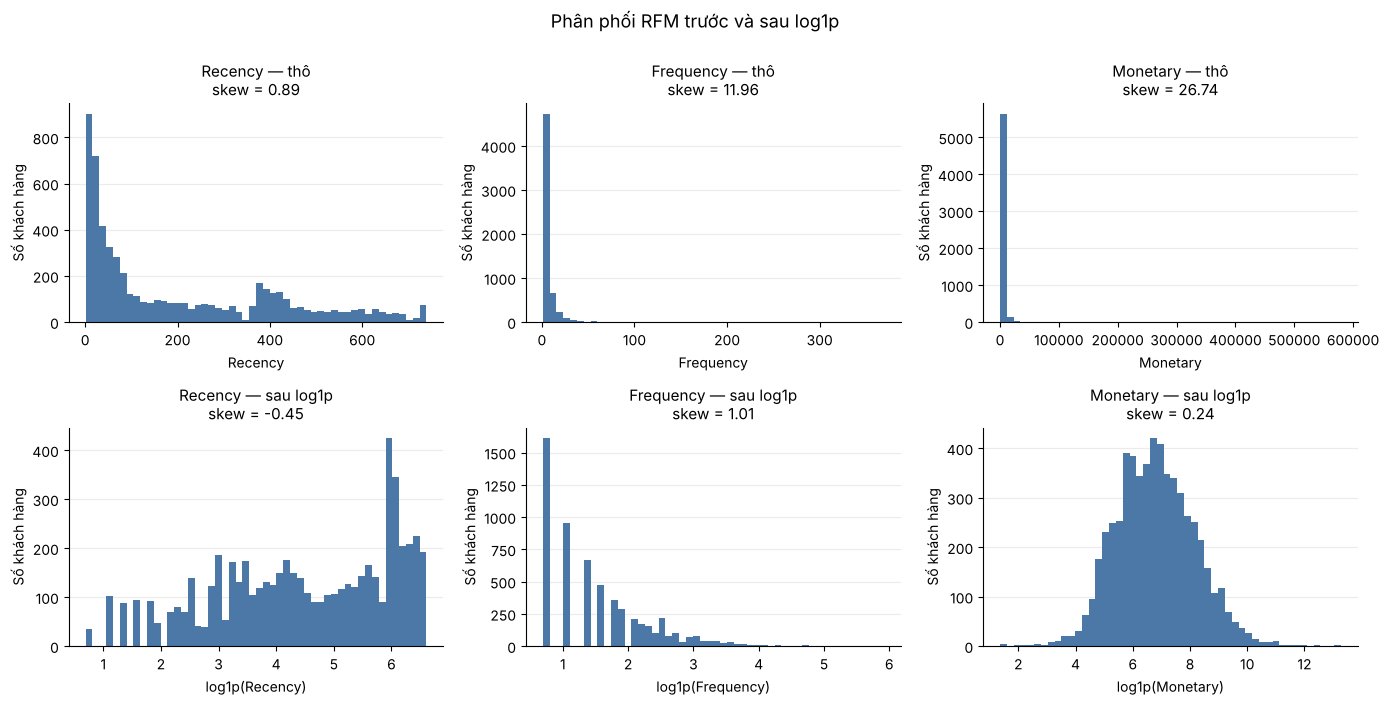

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for j, col in enumerate(COLS):
    ax = axes[0, j]
    ax.hist(rfm[col], bins=50, color=COLOR)
    ax.set_title(f'{col} — thô\nskew = {rfm[col].skew():.2f}', fontsize=11)
    ax.set_xlabel(col)

    ax = axes[1, j]
    ax.hist(rfm_log[f'{col}_log'], bins=50, color=COLOR)
    ax.set_title(f'{col} — sau log1p\nskew = {rfm_log[f"{col}_log"].skew():.2f}',
                 fontsize=11)
    ax.set_xlabel(f'log1p({col})')

for ax in axes.flat:
    ax.set_ylabel('Số khách hàng')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='y', alpha=0.25)
    ax.set_axisbelow(True)

fig.suptitle('Phân phối RFM trước và sau log1p', fontsize=13, y=1.00)
fig.tight_layout()
plt.show()

---

## 5. Chuẩn hóa bằng `StandardScaler`

### 5.1 Vì sao vẫn cần chuẩn hóa sau khi đã log

Sau `log1p`, ba chiều **vẫn ở ba thang khác nhau**. K-Means dùng khoảng cách
Euclidean, tức cộng bình phương chênh lệch của cả ba chiều lại:

$$d^2 = (\Delta R)^2 + (\Delta F)^2 + (\Delta M)^2$$

Chiều nào có phương sai lớn hơn sẽ chi phối tổng này, khiến cụm thực chất chỉ
phản ánh chiều đó. Chuẩn hóa đưa cả ba về cùng $\sigma = 1$ nên chúng đóng góp
ngang nhau.

### 5.2 Vì sao không được đảo thứ tự

Nếu chuẩn hóa trước rồi log sau, kết quả sẽ **sai mà không báo lỗi**.

`log1p(x)` xác định khi $x > -1$. Với dữ liệu lệch phải, z-score nhỏ nhất là
$-\mu/\sigma$, và outlier bơm $\sigma$ lên lớn nên tỉ số này thường nhỏ hơn 1.
Kết quả: mọi giá trị vẫn lớn hơn $-1$, `log1p` chạy êm, không `NaN`, không
exception — nhưng độ phân tách giữa các khách bị giảm hàng chục lần.

Lý do khái niệm: log sửa lệch bằng cách tác động lên **tỉ lệ**, mà tỉ lệ chỉ có
nghĩa khi mốc 0 là mốc gốc thật. Z-score **dịch mốc 0** về trung bình, phá hủy
cấu trúc tỉ lệ. Một khi đã dịch gốc tọa độ, cơ hội sửa lệch mất vĩnh viễn.

In [10]:
scaler = StandardScaler()

rfm_scaled = pd.DataFrame(
    scaler.fit_transform(rfm_log),
    index=rfm_log.index,
    columns=['R_scaled', 'F_scaled', 'M_scaled'],
)

print('Trung bình và độ lệch chuẩn sau khi chuẩn hóa:')
summary = pd.DataFrame({
    'mean'      : rfm_scaled.mean(),
    'std (ddof=0)': rfm_scaled.std(ddof=0),
    'std (ddof=1)': rfm_scaled.std(),
})
print(summary.to_string())

Trung bình và độ lệch chuẩn sau khi chuẩn hóa:
           mean  std (ddof=0)  std (ddof=1)
R_scaled -0.000         1.000         1.000
F_scaled -0.000         1.000         1.000
M_scaled  0.000         1.000         1.000


Hai cột `std` khác nhau ở chữ số thập phân thứ tư. Đây không phải lỗi:

| | Chia cho | Giá trị |
|---|---|---|
| `StandardScaler` | $n$ (ddof = 0) | đúng 1,000 |
| `pandas.std()` mặc định | $n-1$ (ddof = 1) | 1,0001 |

Muốn đối chiếu kết quả của `StandardScaler` bằng pandas thì phải dùng `.std(ddof=0)`.

### 5.3 Kiểm chứng: chuẩn hóa không đổi độ lệch

Đây là phần đáng đưa vào báo cáo, vì nó chứng minh bằng số liệu thật rằng
**chuẩn hóa không thay thế được log transform**.

Skewness là moment bậc ba **đã chuẩn hóa**:

$$\text{skew} = E\!\left[\left(\frac{v-\mu}{\sigma}\right)^{3}\right]$$

Biểu thức trong ngoặc chính là công thức z-score. Nên skewness **bất biến dưới
mọi phép biến đổi affine** $v' = av + b$, mà `StandardScaler` chính là một phép
affine với $a = 1/\sigma$, $b = -\mu/\sigma$.

Ba cột dưới đây phải cho thấy: cột 1 khác cột 2 (log có tác dụng), nhưng
cột 2 **trùng khớp** cột 3 (chuẩn hóa không có tác dụng với độ lệch).

In [11]:
proof = pd.DataFrame({
    '1. thô'            : rfm[COLS].skew().values,
    '2. sau log1p'      : rfm_log.skew().values,
    '3. sau log + scale': rfm_scaled.skew().values,
}, index=COLS)
proof['chênh (2) vs (3)'] = (proof['2. sau log1p'] - proof['3. sau log + scale']).abs()

print(proof.to_string())
print()
print('Cột 2 và cột 3 trùng khớp => StandardScaler không ảnh hưởng độ lệch.')
print('=> log1p là bước KHÔNG THỂ BỎ, không thể thay bằng chuẩn hóa.')

           1. thô  2. sau log1p  3. sau log + scale  chênh (2) vs (3)
Recency     0.894        -0.446              -0.446             0.000
Frequency  11.965         1.005               1.005             0.000
Monetary   26.740         0.241               0.241             0.000

Cột 2 và cột 3 trùng khớp => StandardScaler không ảnh hưởng độ lệch.
=> log1p là bước KHÔNG THỂ BỎ, không thể thay bằng chuẩn hóa.


---

## 6. Lưu kết quả

Hai file cho hai mục đích khác nhau:

| File | Nội dung | Dùng cho |
|---|---|---|
| `rfm.parquet` | R, F, M **thô** | diễn giải và đặt tên cụm ở notebook 03 |
| `rfm_scaled.parquet` | R, F, M đã log và chuẩn hóa | **đầu vào thuật toán phân cụm** |

Phải giữ cả hai. Phân cụm chạy trên dữ liệu đã chuẩn hóa, nhưng khi mô tả cụm
cho người đọc thì phải dùng đơn vị gốc — không ai hiểu "cụm này có Monetary
trung bình 1,87" nghĩa là gì.

In [12]:
rfm.to_parquet(RFM_OUT)
rfm_scaled.to_parquet(SCALED_OUT)

print(f'Đã lưu {RFM_OUT}        — {len(rfm):,} khách × {rfm.shape[1]} cột')
print(f'Đã lưu {SCALED_OUT} — {len(rfm_scaled):,} khách × {rfm_scaled.shape[1]} cột')
print()
rfm_scaled.head()

Đã lưu data/rfm.parquet        — 5,839 khách × 4 cột
Đã lưu data/rfm_scaled.parquet — 5,839 khách × 3 cột



,R_scaled,F_scaled,M_scaled
Customer ID,,,
12346,1.180,-0.553,-1.202
12347,-2.017,0.810,1.239
12348,-0.082,0.307,0.450
12349,-0.964,-0.196,1.028
12350,0.833,-1.057,-0.803


---

## 7. Tổng kết

**Đã hoàn thành**

- Tính RFM cho từng khách hàng, mốc Recency lấy bằng ngày cuối cộng một ngày
- Định lượng độ lệch của cả ba chiều bằng skewness và tỉ lệ max/median:
  Monetary lệch cực mạnh (skewness 26,7; max gấp 680 lần median)
- Áp dụng `log1p` để sửa hình dạng phân phối: skewness của Monetary giảm từ 26,7 xuống 0,24
- Áp dụng `StandardScaler` để cân bằng thang đo giữa ba chiều
- Chứng minh bằng số liệu rằng chuẩn hóa không thay thế được log transform

**Ràng buộc chuyển sang notebook tiếp theo**

Số khách hàng quyết định tính khả thi của Agglomerative Clustering, vốn cần bộ
nhớ $O(n^2)$ cho ma trận khoảng cách. Ước lượng trước khi chạy:

```python
n = len(rfm_scaled)
gb = n * (n - 1) / 2 * 8 / 1024**3
```


**Bước tiếp theo:** `03_clustering.ipynb` — K-Means, Agglomerative, DBSCAN;
chọn $K$ bằng Elbow, Silhouette và Davies-Bouldin; profile và đặt tên cụm.